##### In this Python notebook, I will be loading the cifar-10 dataset, through torchvision.datasets, and I will create a Convolutional Neural Network model, and train that model, and evaluate it and try to improve it's accuracy

In [1]:
import torch 
import matplotlib.pyplot as plt
import torchvision
import torchmetrics

from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix
from torch import nn
from torchvision import datasets
from torchvision.transforms import ToTensor 
from torch.utils.data import DataLoader

In [2]:
train_data = datasets.CIFAR10(root="data",
                             train=True,            
                             download=True,
                             transform=torchvision.transforms.ToTensor()    #We want to convert the PIL images individually into Tensors so we can work with PyTorch
                             )

test_data = datasets.CIFAR10(root="data",
                           train=False,
                           download=True,
                           transform=ToTensor())

Files already downloaded and verified
Files already downloaded and verified


In [3]:
print(train_data)
print(test_data)

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset CIFAR10
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: ToTensor()


In [4]:
BATCH_SIZE = 32
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True)        #So that the model tries to learn the actual pattern, rather than learning the locations of the images

test_dataloader = DataLoader(dataset=test_data,
                            batch_size=BATCH_SIZE,
                            shuffle=False)

In [5]:
image_batch,label_batch = next(iter(train_dataloader))
print(image_batch.shape)

torch.Size([32, 3, 32, 32])


In [6]:
print(label_batch[:10])

tensor([3, 5, 3, 7, 3, 9, 5, 6, 4, 6])


##### Let' visualise some images using matplotlib

In [7]:
class_names = train_data.classes
print(class_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


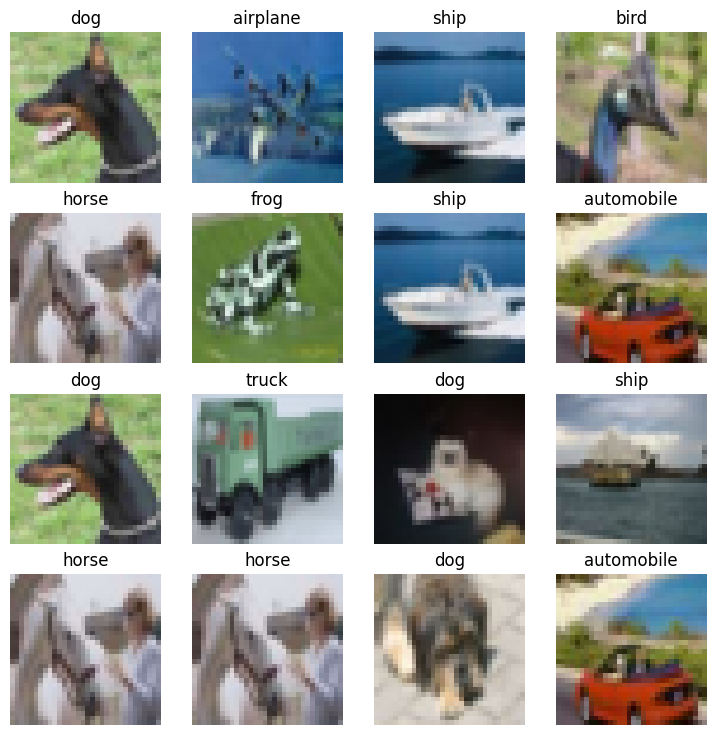

In [8]:
torch.manual_seed(42)     # For reproducibility
fig = plt.figure(figsize=(9,9))
rows,cols=4,4
for i in range(1,rows*cols+1):
    random_idx = torch.randint(0,len(image_batch),size=[1]).item()
    img,label = image_batch[random_idx], label_batch[random_idx]
    np_image = img.permute(1,2,0)     #PyTorch works as NCHW but Matplotlib requires either only height and width or NHWC
    fig.add_subplot(rows,cols,i)
    plt.imshow(np_image)
    plt.title(class_names[label])
    plt.axis(False)

In [9]:
# So first let's set up device agnostic code:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


##### Let's now build the architecture of our model. I will first create a Linear activations only model, as my baseline model and then I will try to imrpove it

In [10]:
class LinearModel(nn.Module):
    def __init__(self,
                input_shape:int,
                hidden_units:int,
                output_shape:int):
        super().__init__()
        self.LinearLayerStack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape,
                     out_features=hidden_units),
            nn.Linear(in_features=hidden_units,
                      out_features=hidden_units),
            nn.Linear(in_features=hidden_units,
                      out_features=output_shape)
        )

    def forward(self,x):
        return self.LinearLayerStack(x)

In [11]:
#Setting a model up
model_0 = LinearModel(input_shape = 3*32*32,
                     hidden_units=128,
                     output_shape=len(class_names)).to(device)
print(model_0)

LinearModel(
  (LinearLayerStack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [12]:
# Setup loss function, optimizer and accuracy_fn(Evaluation metrics) 
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_0.parameters(),
                            lr=0.001)

def accuracy_fn(y_true,y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [13]:
#creating a timer, to find the time taken for training
from timeit import default_timer as timer
def print_train_time(start, end, device=None):
    total_time = end - start
    print(f"\nTrain time on {device}: {total_time:.3f} seconds")
    return total_time

In [14]:
def train_step(model:torch.nn.Module,
              data_loader:torch.utils.data.DataLoader,
              optimizer: torch.optim.Optimizer,
              loss_fn:torch.nn.Module,
              accuracy_fn,
              device:torch.device = device):

    train_loss,train_acc = 0,0
    model.to(device)
    model.train()
    for batch, (X,y) in enumerate(data_loader):
        X,y = X.to(device),y.to(device)

        #1 Forward pass
        y_pred = model(X)

        #2 Calculate loss and accuracy 
        loss = loss_fn(y_pred,y)
        train_loss+=loss
        train_acc += accuracy_fn(y_true = y, y_pred=y_pred.argmax(dim=1))   #argmax because we wan't the labels, not the probabilities

        #3 Optimizer zero grad
        optimizer.zero_grad()

        #4. Loss backwards(backpropogation)
        loss.backward()

        #5. Optimizer step(Gradient Descent)
        optimizer.step()

    train_loss /= len(data_loader)    #calculating the metrics per batch
    train_acc /= len(data_loader)

    print(f"Training Loss: {train_loss:.4f} |  Training Accuracy: {train_acc:.2f}%") 

In [15]:
def test_step(model:torch.nn.Module,
             data_loader:torch.utils.data.DataLoader,
             loss_fn:torch.nn.Module,
             accuracy_fn,
             device:torch.device=device):

    test_loss,test_acc=0,0
    model.to(device)
    model.eval()
    with torch.inference_mode():
        for X_test,y_test in data_loader:
            X_test,y_test=X_test.to(device),y_test.to(device)
            
            #1 Forward pass
            y_test_pred = model(X_test)

            #2 Calculate loss and accuracy 
            test_loss += loss_fn(y_test_pred,y_test)
            test_acc+=accuracy_fn(y_true=y_test,y_pred=y_test_pred.argmax(dim=1))

        test_loss /=len(data_loader)
        test_acc /=len(data_loader)
        print(f"Testing Loss: {test_loss:.4f} |  Testing Accuracy: {test_acc:.2f}%") 

In [16]:
#Running the training and testing loop on model_0
torch.manual_seed(42)
torch.cuda.manual_seed(42)

train_time_start = timer()
epochs = 3
for epoch in range(epochs):
    print(f"Epoch {epoch}\n--------")
    train_step(model=model_0, data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

    test_step(model=model_0,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_0 = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0
--------
Training Loss: 1.9238 |  Training Accuracy: 31.00%
Testing Loss: 1.8429 |  Testing Accuracy: 33.96%
Epoch 1
--------
Training Loss: 1.8326 |  Training Accuracy: 35.14%
Testing Loss: 1.8052 |  Testing Accuracy: 36.45%
Epoch 2
--------
Training Loss: 1.8062 |  Training Accuracy: 36.44%
Testing Loss: 1.8657 |  Testing Accuracy: 32.94%

Train time on cuda: 25.907 seconds


##### As we can see the accuracy is really really bad. It was expected as our model architecture comrpised only of linear activation functions only, and the images have non linear aspects to them
##### So let's now make another architecture with a combination of linear and non linear activation functions and see how that works

In [17]:
class LinearAndNonLinearModel(nn.Module):
    def __init__(self,
                input_shape:int,
                hidden_units:int,
                output_shape:int):
        super().__init__()
        self.LayerStack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape,
                      out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units,
                      out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units,
                      out_features=output_shape)
        )

    def forward(self,x):
        return self.LayerStack(x)

In [18]:
#Instantiating a model
model_1 = LinearAndNonLinearModel(input_shape=3*32*32,
                                 hidden_units=128,
                                 output_shape=len(class_names)).to(device)
print(model_1)

LinearAndNonLinearModel(
  (LayerStack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [19]:
# Setting up evaluating metrics
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(),
                            lr=0.001)
#accuracy_fn is defined earlier, it's going to remain the same for all

In [20]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

train_time_start = timer()
epochs = 3
for epoch in range(epochs):
    print(f"Epoch {epoch}  \n--------")
    train_step(model=model_1,data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

    test_step(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_1 = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0  
--------
Training Loss: 1.8437 |  Training Accuracy: 33.20%
Testing Loss: 1.7117 |  Testing Accuracy: 38.19%
Epoch 1  
--------
Training Loss: 1.6642 |  Training Accuracy: 40.41%
Testing Loss: 1.6008 |  Testing Accuracy: 42.19%
Epoch 2  
--------
Training Loss: 1.5905 |  Training Accuracy: 42.73%
Testing Loss: 1.5494 |  Testing Accuracy: 44.19%

Train time on cuda: 26.862 seconds


##### Well these are very interesting results. I will do two things and see the results again
##### 1] Increase the hidden units to 128,
##### 2] Increase the epochs, as 3 epochs is very very less, I had kept 3 epochs to see if everything works, because if I had started with higher epochs, and somethign was wrong I would have had to wait much longer before I would have known

In [21]:
#Setting a model up
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_0 = LinearModel(input_shape = 3*32*32,
                     hidden_units=128,
                     output_shape=len(class_names)).to(device)
print(model_0)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_0.parameters(),
                            lr=0.001)

train_time_start = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch {epoch}\n--------")
    train_step(model=model_0, data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

    test_step(model=model_0,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_0 = print_train_time(start=train_time_start,end=train_time_end,device=device)

LinearModel(
  (LinearLayerStack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Epoch 0
--------
Training Loss: 1.9258 |  Training Accuracy: 31.21%
Testing Loss: 1.8071 |  Testing Accuracy: 36.81%
Epoch 1
--------
Training Loss: 1.8349 |  Training Accuracy: 35.11%
Testing Loss: 1.8297 |  Testing Accuracy: 33.98%
Epoch 2
--------
Training Loss: 1.8075 |  Training Accuracy: 36.23%
Testing Loss: 1.8267 |  Testing Accuracy: 34.59%
Epoch 3
--------
Training Loss: 1.7882 |  Training Accuracy: 37.45%
Testing Loss: 1.8090 |  Testing Accuracy: 36.89%
Epoch 4
--------
Training Loss: 1.7775 |  Training Accuracy: 37.89%
Testing Loss: 1.7830 |  Testing Accuracy: 36.86%
Epoch 5
--------
Training Loss: 1.7664 |  Training Accuracy: 38.37%
Testing Loss: 1.7398 |  Testing Accuracy: 39.65%
Epoch 6
--------


In [22]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_1 = LinearAndNonLinearModel(input_shape=3*32*32,
                                 hidden_units=128,
                                 output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_1.parameters(),
                            lr=0.001)
train_time_start = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch {epoch}  \n--------")
    train_step(model=model_1,data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

    test_step(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_1 = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0  
--------
Training Loss: 1.8535 |  Training Accuracy: 32.82%
Testing Loss: 1.7678 |  Testing Accuracy: 36.09%
Epoch 1  
--------
Training Loss: 1.6822 |  Training Accuracy: 39.45%
Testing Loss: 1.6715 |  Testing Accuracy: 39.20%
Epoch 2  
--------
Training Loss: 1.6118 |  Training Accuracy: 42.14%
Testing Loss: 1.5908 |  Testing Accuracy: 43.43%
Epoch 3  
--------
Training Loss: 1.5622 |  Training Accuracy: 43.93%
Testing Loss: 1.5632 |  Testing Accuracy: 43.82%
Epoch 4  
--------
Training Loss: 1.5355 |  Training Accuracy: 44.91%
Testing Loss: 1.5262 |  Testing Accuracy: 45.70%
Epoch 5  
--------
Training Loss: 1.5090 |  Training Accuracy: 45.95%
Testing Loss: 1.5203 |  Testing Accuracy: 45.95%
Epoch 6  
--------
Training Loss: 1.4858 |  Training Accuracy: 46.82%
Testing Loss: 1.5238 |  Testing Accuracy: 45.44%
Epoch 7  
--------
Training Loss: 1.4662 |  Training Accuracy: 47.34%
Testing Loss: 1.4939 |  Testing Accuracy: 46.51%
Epoch 8  
--------
Training Loss: 1.4528 |  Trai

##### Okay, so we can see that 10 epochs is a good number, as the increase in accuracy is very less, and the non linear model, was able to learn much better the patterns and is performing almost 10 percent better than the linear model
##### BUT, 46 percent accuracy is still very less, and so we finally will make a CNN architecture, first with only 2 CNN blocks, and then we will experiment by adding CNN blocks, and changing the hidden units and other thing
##### So let's make CNN architecture 

In [23]:
class CNNModel(nn.Module):
    def __init__(self,
                 input_shape:int,
                 hidden_units:int,
                 output_shape:int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units, out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.ReLU(),
            nn.Conv2d(in_channels = hidden_units, out_channels=hidden_units,kernel_size=3,padding=0,stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*5*5,   #We will calculate this later by using a dummy variable
                     out_features=output_shape)
        )
    def forward(self,x):
        x = self.conv_block_1(x)
        #print(f"Output shape of conv_block_1: {x.shape}")
        x=self.conv_block_2(x)
        #print(f"Output shape of conv_block_2: {x.shape}")
        #x=self.conv_block_3(x)
        #print(f"Output shape of conv_block_2: {x.shape}")
        x= self.classifier(x)
        #print(f"Output shape of classifier: {x.shape}")
        return x

In [24]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_2 = CNNModel(input_shape=3,
                  hidden_units=32,
                  output_shape=len(class_names)).to(device)
print(model_2)

CNNModel(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=800, out_features=10, bias=True)
  )
)


In [25]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2.parameters(),
                             lr=0.001)

In [26]:
#image,label = train_data[0]
#print(image.shape)

In [27]:
#image=image.to(device).unsqueeze(dim=0)

##### We did this dummy test just so we could set the input_features value of the Linear classifier of the classifier architecture, and now I have updated it

In [28]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

train_time_start_model_2 = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=model_2,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device = device)

    test_step(model=model_2,
               data_loader=test_dataloader,
               loss_fn=loss_fn,
               accuracy_fn=accuracy_fn,
               device = device)

train_time_end_model_2 = timer()
total_train_time_on_model_2 = print_train_time(start=train_time_start_model_2,end=train_time_end_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.6126 |  Training Accuracy: 41.17%
Testing Loss: 1.3982 |  Testing Accuracy: 50.04%
Epoch: 1
--------
Training Loss: 1.2705 |  Training Accuracy: 54.92%
Testing Loss: 1.1699 |  Testing Accuracy: 58.37%
Epoch: 2
--------
Training Loss: 1.1176 |  Training Accuracy: 60.77%
Testing Loss: 1.1404 |  Testing Accuracy: 59.69%
Epoch: 3
--------
Training Loss: 1.0238 |  Training Accuracy: 64.19%
Testing Loss: 1.0211 |  Testing Accuracy: 63.82%
Epoch: 4
--------
Training Loss: 0.9615 |  Training Accuracy: 66.43%
Testing Loss: 1.0544 |  Testing Accuracy: 63.43%
Epoch: 5
--------
Training Loss: 0.9100 |  Training Accuracy: 68.24%
Testing Loss: 0.9646 |  Testing Accuracy: 65.92%
Epoch: 6
--------
Training Loss: 0.8717 |  Training Accuracy: 69.72%
Testing Loss: 0.9922 |  Testing Accuracy: 65.58%
Epoch: 7
--------
Training Loss: 0.8431 |  Training Accuracy: 70.76%
Testing Loss: 0.9241 |  Testing Accuracy: 67.55%
Epoch: 8
--------
Training Loss: 0.8155 |  Training Accu

#### That is a massive imporvement. But I think maybe trying hidden units as 64 would give us a much better result

In [29]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_3 = CNNModel(input_shape=3,
                  hidden_units=64,
                  output_shape=len(class_names)).to(device)
print(model_3)

CNNModel(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1600, out_features=10, bias=True)
  )
)


In [30]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_3.parameters(),
                             lr=0.001)

In [31]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

train_time_start_model_3 = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=model_3,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device = device)

    test_step(model=model_3,
               data_loader=test_dataloader,
               loss_fn=loss_fn,
               accuracy_fn=accuracy_fn,
               device = device)

train_time_end_model_3 = timer()
total_train_time_on_model_3 = print_train_time(start=train_time_start_model_3,end=train_time_end_model_3,device=device)

Epoch: 0
--------
Training Loss: 1.5049 |  Training Accuracy: 45.23%
Testing Loss: 1.2276 |  Testing Accuracy: 55.98%
Epoch: 1
--------
Training Loss: 1.1000 |  Training Accuracy: 61.35%
Testing Loss: 0.9910 |  Testing Accuracy: 65.05%
Epoch: 2
--------
Training Loss: 0.9368 |  Training Accuracy: 67.24%
Testing Loss: 0.9258 |  Testing Accuracy: 66.98%
Epoch: 3
--------
Training Loss: 0.8392 |  Training Accuracy: 70.84%
Testing Loss: 0.8318 |  Testing Accuracy: 71.50%
Epoch: 4
--------
Training Loss: 0.7725 |  Training Accuracy: 73.13%
Testing Loss: 0.8457 |  Testing Accuracy: 70.65%
Epoch: 5
--------
Training Loss: 0.7166 |  Training Accuracy: 75.10%
Testing Loss: 0.8104 |  Testing Accuracy: 71.95%
Epoch: 6
--------
Training Loss: 0.6756 |  Training Accuracy: 76.73%
Testing Loss: 0.8199 |  Testing Accuracy: 72.22%
Epoch: 7
--------
Training Loss: 0.6435 |  Training Accuracy: 77.51%
Testing Loss: 0.7968 |  Testing Accuracy: 73.56%
Epoch: 8
--------
Training Loss: 0.6072 |  Training Accu

##### Well we can see that the model has performed slightly better, with an increase in test percentage to 74 percent , so increase by 4 percent. However the gap between training and testing accuracy might suggest that the model is overfitting. I had even tried with hidden units set as 128 but the model achieved a max test accuracy of 72-73 percent, and the training accuracy was much higher, implying the model was overfitting
##### I had also experimented by adding another kernel layer, and setting its padding as one, otherwise the output dimensions would be 0, and it gave no real improverment, and even took more time to compute. So the sweet spot that I got was 64 hidden units with two convolution blocks

In [32]:
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device:torch.device=device):
    loss,acc=0,0
    model.to(device)
    model.eval()
    with torch.inference_mode():
        for X,y in data_loader:
            X,y = X.to(device),y.to(device)
            y_pred = model(X)

            loss+=loss_fn(y_pred,y)
            acc+=accuracy_fn(y_true=y,y_pred=y_pred.argmax(dim=1))

        loss/=len(data_loader)
        acc/=len(data_loader)

    return {"model_name":model.__class__.__name__,   #only works when model was created with a class
        "model_loss":loss.item(),
        "model_acc":acc}

In [33]:
model_0_results = eval_model(model=model_0,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn,
                            device=device)
model_1_results = eval_model(model=model_1,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_2_results = eval_model(model=model_2,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_3_results = eval_model(model=model_3,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)

In [34]:
print(model_0_results)
print(model_1_results)
print(model_2_results)
print(model_3_results)

{'model_name': 'LinearModel', 'model_loss': 1.7787278890609741, 'model_acc': 36.88099041533546}
{'model_name': 'LinearAndNonLinearModel', 'model_loss': 1.508653163909912, 'model_acc': 45.846645367412144}
{'model_name': 'CNNModel', 'model_loss': 0.9204912781715393, 'model_acc': 68.67012779552715}
{'model_name': 'CNNModel', 'model_loss': 0.8198652267456055, 'model_acc': 72.57388178913737}


In [35]:
import pandas as pd

In [36]:
model_results= pd.DataFrame([model_0_results,model_1_results,model_2_results,model_3_results])
model_results["Training Time"] = ([total_train_time_on_model_0,total_train_time_on_model_1,total_train_time_on_model_2,total_train_time_on_model_3])
print(model_results)

                model_name  model_loss  model_acc  Training Time
0              LinearModel    1.778728  36.880990      87.933560
1  LinearAndNonLinearModel    1.508653  45.846645      90.599980
2                 CNNModel    0.920491  68.670128     103.429683
3                 CNNModel    0.819865  72.573882     104.633818


#### let's now make a confusion matrix, and plot the confusion matrix

In [37]:
y_preds = []
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_3.eval()
with torch.inference_mode():
    for X,y in test_dataloader:
        X,y=X.to(device),y.to(device)

        y_logits = model_3(X)         #RAw predictions are called logits, which need to be converted to prediction probabilities, which are then converted to labels/targets 
        y_pred = torch.softmax(y_logits,dim=1).argmax(dim=1)
        y_preds.append(y_pred.cpu())      #Because we'll be plotting the confusion matrix using matplotlib which works on numpy, which does not support GPU

    y_pred_tensor = torch.cat(y_preds)    #converts to a single tensor label 

print(y_pred_tensor)

tensor([3, 8, 0,  ..., 5, 1, 7])


In [38]:
confmat = ConfusionMatrix(task="multiclass",
                         num_classes=len(class_names))
confmat_tensor = confmat(preds=y_pred_tensor,target=torch.Tensor(test_data.targets))  #comparing the predicted labels with the actual labels for constructing the confusion matrix 
print(confmat_tensor)

tensor([[797,  12,  60,  12,  27,   5,  20,   8,  33,  26],
        [ 26, 848,   2,   3,   3,   3,  14,   4,  17,  80],
        [ 69,   2, 550,  32, 132,  48, 122,  22,  13,  10],
        [ 21,   8,  74, 436, 113, 159, 130,  32,   9,  18],
        [ 14,   1,  49,  25, 776,  19,  59,  50,   4,   3],
        [  6,   1,  71,  99,  82, 634,  45,  53,   4,   5],
        [  8,   1,  35,  27,  46,  15, 863,   2,   1,   2],
        [ 11,   4,  48,  16,  90,  46,  23, 752,   1,   9],
        [ 90,  33,  20,   8,  19,   4,  14,   9, 778,  25],
        [ 37,  76,   9,   7,   9,   5,   9,   6,  18, 824]])


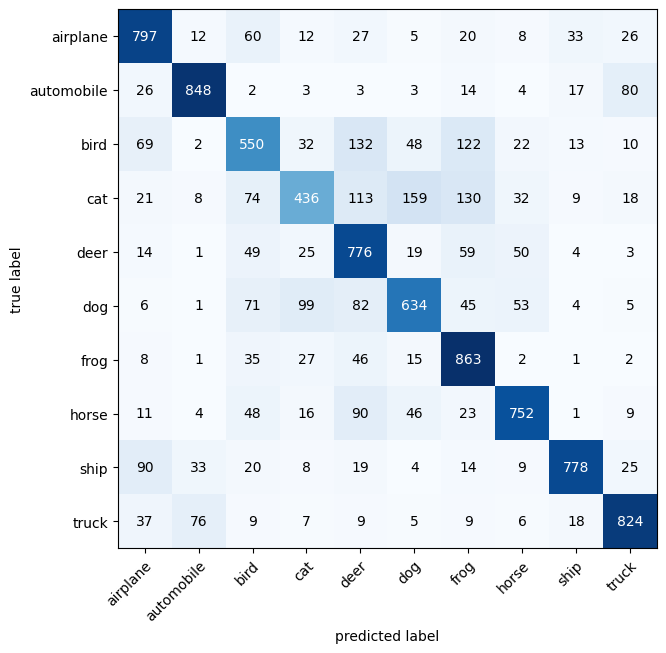

In [39]:
fig,ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),     #it works with matplotlib so it likes working with numpy
    class_names=class_names,
    figsize=(10,7)
)

In [40]:
import random
random.seed(42)
test_samples = []
test_labels = []

for sample,label in random.sample(list(test_data),k=9):
    test_samples.append(sample)
    test_labels.append(label)

test_samples[0].shape

torch.Size([3, 32, 32])

In [41]:
def make_predictions(model:torch.nn.Module,
                     data:list,
                     device:torch.device=device):
    pred_probs = []
    model.to(device)
    model.eval()
    with torch.inference_mode():
        for sample in data:          # The list contains multiple random images tensor, and their labels, so we loop through each of the image
            sample = torch.unsqueeze(sample,dim=0).to(device)    #We are adding a dimension for batch size, so that we can pass it to the model without shape mismatches

            #Forward pass(model outputs raw logits)
            pred_logit = model(sample)

            #Get prediction probabilitty - We get it using softmax for multiclass 
            pred_prob = torch.softmax(pred_logit.squeeze(),dim=0)

            #Get pred_prob off of the GPU for further calculations(like maybe with matplotlib)
            pred_probs.append(pred_prob.cpu())

    #Stack the pred_probs to turn list into Tensor 
    return torch.stack(pred_probs)

Text(0.5, 1.0, 'truck')

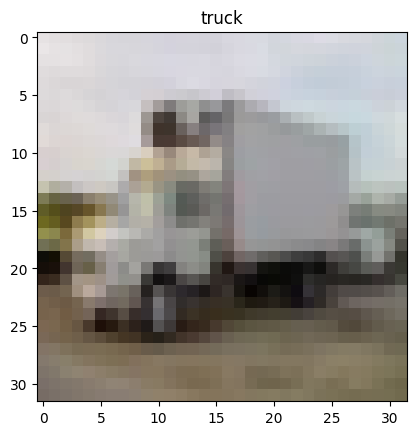

In [42]:
plt.imshow(test_samples[0].permute(1,2,0))
plt.title(class_names[test_labels[0]])

In [43]:
#Make predictions
pred_probs = make_predictions(model=model_3,
                              data=test_samples)

# Converting the pred probabilities to prediction labels and comparing with the test_labels
pred_labels = pred_probs.argmax(dim=1)
print(pred_labels)

tensor([9, 2, 1, 6, 2, 7, 7, 0, 9])


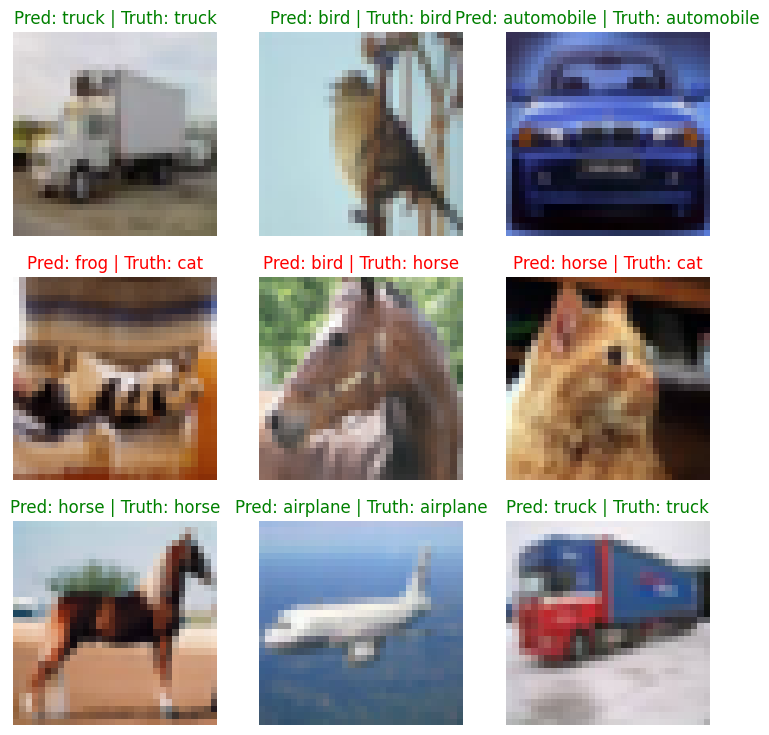

In [44]:
# Plot predictions 
plt.figure(figsize=(9,9))
nrows,ncols=3,3
for i,sample in enumerate(test_samples):
    plt.subplot(nrows,ncols,i+1)

    plt.imshow(sample.permute(1,2,0))

    #Get the predicted label
    pred_label = class_names[pred_labels[i]]

    #Get the true label
    true_label = class_names[test_labels[i]]

    #create a title for the plot 
    title_text = f"Pred: {pred_label} | Truth: {true_label}"

    #Check for equality between predicter and truth label along with color coding 
    if pred_label == true_label :
        plt.title(title_text,c='g')   #green text if prediction same
    else:
        plt.title(title_text,c='r')    #red if wrong 

    plt.axis(False)

In [45]:
#### Now I will run the exact same model runs on my CPU:-
device = "cpu"
print(device)

cpu


In [46]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_0_cpu = LinearModel(input_shape = 3*32*32,
                     hidden_units=128,
                     output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_0_cpu.parameters(),
                            lr=0.001)

train_time_start = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch {epoch}\n--------")
    train_step(model=model_0_cpu, data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

    test_step(model=model_0_cpu,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_0_cpu = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0
--------
Training Loss: 1.9258 |  Training Accuracy: 31.21%
Testing Loss: 1.8071 |  Testing Accuracy: 36.81%
Epoch 1
--------
Training Loss: 1.8349 |  Training Accuracy: 35.12%
Testing Loss: 1.8296 |  Testing Accuracy: 33.98%
Epoch 2
--------
Training Loss: 1.8075 |  Training Accuracy: 36.22%
Testing Loss: 1.8273 |  Testing Accuracy: 34.48%
Epoch 3
--------
Training Loss: 1.7882 |  Training Accuracy: 37.43%
Testing Loss: 1.8084 |  Testing Accuracy: 36.75%
Epoch 4
--------
Training Loss: 1.7776 |  Training Accuracy: 37.99%
Testing Loss: 1.7791 |  Testing Accuracy: 37.02%
Epoch 5
--------
Training Loss: 1.7661 |  Training Accuracy: 38.45%
Testing Loss: 1.7389 |  Testing Accuracy: 39.64%
Epoch 6
--------
Training Loss: 1.7562 |  Training Accuracy: 38.88%
Testing Loss: 1.7697 |  Testing Accuracy: 37.87%
Epoch 7
--------
Training Loss: 1.7523 |  Training Accuracy: 39.15%
Testing Loss: 1.7551 |  Testing Accuracy: 37.93%
Epoch 8
--------
Training Loss: 1.7467 |  Training Accuracy: 39.

In [47]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
model_1_cpu = LinearAndNonLinearModel(input_shape=3*32*32,
                                 hidden_units=128,
                                 output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=model_1_cpu.parameters(),
                            lr=0.001)
train_time_start = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch {epoch}  \n--------")
    train_step(model=model_1_cpu,data_loader=train_dataloader,optimizer=optimizer,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

    test_step(model=model_1_cpu,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end = timer()
total_train_time_on_model_1_cpu = print_train_time(start=train_time_start,end=train_time_end,device=device)

Epoch 0  
--------
Training Loss: 1.8535 |  Training Accuracy: 32.82%
Testing Loss: 1.7678 |  Testing Accuracy: 36.09%
Epoch 1  
--------
Training Loss: 1.6822 |  Training Accuracy: 39.45%
Testing Loss: 1.6715 |  Testing Accuracy: 39.20%
Epoch 2  
--------
Training Loss: 1.6118 |  Training Accuracy: 42.14%
Testing Loss: 1.5908 |  Testing Accuracy: 43.43%
Epoch 3  
--------
Training Loss: 1.5622 |  Training Accuracy: 43.93%
Testing Loss: 1.5632 |  Testing Accuracy: 43.82%
Epoch 4  
--------
Training Loss: 1.5355 |  Training Accuracy: 44.91%
Testing Loss: 1.5262 |  Testing Accuracy: 45.70%
Epoch 5  
--------
Training Loss: 1.5090 |  Training Accuracy: 45.95%
Testing Loss: 1.5203 |  Testing Accuracy: 45.95%
Epoch 6  
--------
Training Loss: 1.4858 |  Training Accuracy: 46.82%
Testing Loss: 1.5238 |  Testing Accuracy: 45.44%
Epoch 7  
--------
Training Loss: 1.4662 |  Training Accuracy: 47.34%
Testing Loss: 1.4939 |  Testing Accuracy: 46.51%
Epoch 8  
--------
Training Loss: 1.4528 |  Trai

In [48]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_2_cpu = CNNModel(input_shape=3,
                  hidden_units=32,
                  output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2_cpu.parameters(),
                             lr=0.001)
train_time_start_model_2 = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=model_2_cpu,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device = device)

    test_step(model=model_2_cpu,
               data_loader=test_dataloader,
               loss_fn=loss_fn,
               accuracy_fn=accuracy_fn,
               device = device)

train_time_end_model_2 = timer()
total_train_time_on_model_2_cpu = print_train_time(start=train_time_start_model_2,end=train_time_end_model_2,device=device)

Epoch: 0
--------
Training Loss: 1.6144 |  Training Accuracy: 41.22%
Testing Loss: 1.3718 |  Testing Accuracy: 50.65%
Epoch: 1
--------
Training Loss: 1.2615 |  Training Accuracy: 55.21%
Testing Loss: 1.1800 |  Testing Accuracy: 58.02%
Epoch: 2
--------
Training Loss: 1.1102 |  Training Accuracy: 61.30%
Testing Loss: 1.0777 |  Testing Accuracy: 61.94%
Epoch: 3
--------
Training Loss: 1.0193 |  Training Accuracy: 64.37%
Testing Loss: 1.0361 |  Testing Accuracy: 63.47%
Epoch: 4
--------
Training Loss: 0.9574 |  Training Accuracy: 66.77%
Testing Loss: 0.9787 |  Testing Accuracy: 65.87%
Epoch: 5
--------
Training Loss: 0.9044 |  Training Accuracy: 68.77%
Testing Loss: 0.9768 |  Testing Accuracy: 65.99%
Epoch: 6
--------
Training Loss: 0.8691 |  Training Accuracy: 69.57%
Testing Loss: 0.9301 |  Testing Accuracy: 67.42%
Epoch: 7
--------
Training Loss: 0.8347 |  Training Accuracy: 70.99%
Testing Loss: 0.9409 |  Testing Accuracy: 67.72%
Epoch: 8
--------
Training Loss: 0.8081 |  Training Accu

In [49]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

model_3_cpu = CNNModel(input_shape=3,
                  hidden_units=64,
                  output_shape=len(class_names)).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_3_cpu.parameters(),
                             lr=0.001)
train_time_start_model_3 = timer()
epochs = 10
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n--------")
    train_step(model=model_3_cpu,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device = device)

    test_step(model=model_3_cpu,
               data_loader=test_dataloader,
               loss_fn=loss_fn,
               accuracy_fn=accuracy_fn,
               device = device)

train_time_end_model_3 = timer()
total_train_time_on_model_3_cpu = print_train_time(start=train_time_start_model_3,end=train_time_end_model_3,device=device)

Epoch: 0
--------
Training Loss: 1.5230 |  Training Accuracy: 44.46%
Testing Loss: 1.2453 |  Testing Accuracy: 56.29%
Epoch: 1
--------
Training Loss: 1.1214 |  Training Accuracy: 60.29%
Testing Loss: 1.1177 |  Testing Accuracy: 59.86%
Epoch: 2
--------
Training Loss: 0.9559 |  Training Accuracy: 66.76%
Testing Loss: 0.9300 |  Testing Accuracy: 67.83%
Epoch: 3
--------
Training Loss: 0.8606 |  Training Accuracy: 70.12%
Testing Loss: 0.8513 |  Testing Accuracy: 70.82%
Epoch: 4
--------
Training Loss: 0.7966 |  Training Accuracy: 72.40%
Testing Loss: 0.8354 |  Testing Accuracy: 71.10%
Epoch: 5
--------
Training Loss: 0.7468 |  Training Accuracy: 73.88%
Testing Loss: 0.8196 |  Testing Accuracy: 71.80%
Epoch: 6
--------
Training Loss: 0.7045 |  Training Accuracy: 75.49%
Testing Loss: 0.8089 |  Testing Accuracy: 72.65%
Epoch: 7
--------
Training Loss: 0.6718 |  Training Accuracy: 76.54%
Testing Loss: 0.7801 |  Testing Accuracy: 73.00%
Epoch: 8
--------
Training Loss: 0.6334 |  Training Accu

In [50]:
model_0_cpu_results = eval_model(model=model_0_cpu,
                            data_loader=test_dataloader,
                            loss_fn=loss_fn,
                            accuracy_fn=accuracy_fn,
                            device=device)
model_1_cpu_results = eval_model(model=model_1_cpu,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_2_cpu_results = eval_model(model=model_2_cpu,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
model_3_cpu_results = eval_model(model=model_3_cpu,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn,
                             device=device)
print(model_0_cpu_results)
print(model_1_cpu_results)
print(model_2_cpu_results)
print(model_3_cpu_results)

{'model_name': 'LinearModel', 'model_loss': 1.7814637422561646, 'model_acc': 36.9408945686901}
{'model_name': 'LinearAndNonLinearModel', 'model_loss': 1.508653163909912, 'model_acc': 45.846645367412144}
{'model_name': 'CNNModel', 'model_loss': 0.8759927749633789, 'model_acc': 69.4888178913738}
{'model_name': 'CNNModel', 'model_loss': 0.7896443009376526, 'model_acc': 74.03154952076677}


In [51]:
cpu_model_results = pd.DataFrame([model_0_cpu_results,model_1_cpu_results,model_2_cpu_results,model_3_cpu_results])
model_results = pd.concat([model_results,cpu_model_results],ignore_index=True)
print(model_results)

                model_name  model_loss  model_acc  Training Time
0              LinearModel    1.778728  36.880990      87.933560
1  LinearAndNonLinearModel    1.508653  45.846645      90.599980
2                 CNNModel    0.920491  68.670128     103.429683
3                 CNNModel    0.819865  72.573882     104.633818
4              LinearModel    1.781464  36.940895            NaN
5  LinearAndNonLinearModel    1.508653  45.846645            NaN
6                 CNNModel    0.875993  69.488818            NaN
7                 CNNModel    0.789644  74.031550            NaN


In [52]:
model_results.loc[4:7,"Training Time"] = [total_train_time_on_model_0_cpu,total_train_time_on_model_1_cpu,total_train_time_on_model_2_cpu,total_train_time_on_model_3_cpu]

In [53]:
print(model_results)

                model_name  model_loss  model_acc  Training Time
0              LinearModel    1.778728  36.880990      87.933560
1  LinearAndNonLinearModel    1.508653  45.846645      90.599980
2                 CNNModel    0.920491  68.670128     103.429683
3                 CNNModel    0.819865  72.573882     104.633818
4              LinearModel    1.781464  36.940895      98.836040
5  LinearAndNonLinearModel    1.508653  45.846645      91.529616
6                 CNNModel    0.875993  69.488818     323.667870
7                 CNNModel    0.789644  74.031550     791.579993


#### Since the accuracies are almost the same, so the confusion matrix and graphs would come out as same

In [54]:
fig.savefig("Plot_images/confusion_matrix.png",
            dpi=300,
            bbox_inches="tight")

In [56]:
from pathlib import Path 

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME = "CNN_64_GPU.pth"
MODEL_SAVE_PATH = MODEL_PATH/MODEL_NAME
torch.save(obj = model_3.state_dict(),f=MODEL_SAVE_PATH) 

#### Saving the model's parameters, so that they can be loaded in different programs and used